## 0. Persiapan Lingkungan dan Dataset

In [1]:
# ==== IDENTITAS (ubah sesuai data Anda) ====
NAMA  = "Khansa Nisrina"
NIM   = "2330511089"          # SEED = 4 digit terakhir NIM
KELAS = "TI-7B"

import os, sys
SEED = int(NIM[-4:])
DI_COLAB = "google.colab" in sys.modules
ROOT = f"/content/simuteh-{NIM}" if DI_COLAB else os.path.abspath(f"simuteh-{NIM}")
for sub in ["data", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(os.path.join(ROOT, sub), exist_ok=True)
os.chdir(ROOT)
print("Folder kerja :", ROOT)
print("SEED         :", SEED)

Folder kerja : /content/simuteh-2330511089
SEED         : 1089


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
%%writefile src/buat_dataset_sintetis.py
"""
buat_dataset_sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.

Keluaran (folder data/sintetis/):
  citra/    citra berwarna hasil "pemotretan" (dengan gangguan cahaya dan derau)
  bersih/   citra yang sama tanpa gangguan (acuan mutu)
  mask_daun/    mask area daun (255 = daun)
  mask_bercak/  mask area bercak penyakit (255 = bercak)
  label.csv     nama_file, kelas, kondisi_cahaya, persen_bercak
"""
import os
import csv
import cv2
import numpy as np

SEED = 1089          # GANTI dengan 4 digit terakhir NIM Anda
N_PER_KELAS = 20     # 20 citra x 3 kelas = 60 citra
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")

rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),
                      rng.integers(45, 75)])               # BGR
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    # tulang daun utama dan cabang
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),
                 int(rng.integers(185, 210))]               # BGR pucat
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)    # tepi cokelat
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun                                # bercak hanya di daun


def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)   # separuh teduh
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)                   # derau sensor
    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),
                              rng.integers(185, 215)])      # nampan anyaman
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()


Writing src/buat_dataset_sintetis.py


In [4]:
%%writefile src/utils_cv.py
"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""
import cv2
import numpy as np
import matplotlib.pyplot as plt


def baca(path):
    """Membaca citra dan langsung memberi pesan jelas bila gagal."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img


def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()


def kontras_bercak(kanal, mask_daun, mask_bercak):
    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat.
    Makin besar KB, makin mudah bercak dipisahkan dari daun sehat."""
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)


def statistik(gray):
    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}


Writing src/utils_cv.py


In [5]:
# Pasang SEED sesuai NIM, bangkitkan dataset, lalu pindah ke folder notebook/
import re, subprocess
kode = open("src/buat_dataset_sintetis.py").read()
kode = re.sub(r"^SEED = \d+", f"SEED = {SEED}", kode, count=1, flags=re.M)
open("src/buat_dataset_sintetis.py", "w").write(kode)
keluaran = subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"],
                          capture_output=True, text=True)
print(keluaran.stdout, keluaran.stderr)

# requirements.txt untuk reprodusibilitas
import cv2, numpy, pandas, matplotlib, skimage, PIL
with open("requirements.txt", "w") as f:
    for nm, m in [("opencv-python", cv2), ("numpy", numpy), ("pandas", pandas),
                  ("matplotlib", matplotlib), ("scikit-image", skimage), ("pillow", PIL)]:
        f.write(f"{nm}=={m.__version__}\n")
print(open("requirements.txt").read())

os.chdir(os.path.join(ROOT, "notebook"))   # semua jalur selanjutnya diawali ../

Selesai: 60 citra tersimpan di data/sintetis
 
opencv-python==5.0.0
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-image==0.25.2
pillow==11.3.0



In [6]:
# Pustaka dan fungsi bantu yang dipakai di seluruh notebook
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 90

def muat(nama, folder="citra"):
    """Mengembalikan (citra BGR, mask daun, mask bercak) untuk satu nama berkas."""
    img = baca(f"../data/sintetis/{folder}/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat| (satuan intensitas)."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
print(label.groupby(["kelas", "kondisi_cahaya"]).size().unstack())
print(label.groupby("kelas").persen_bercak.describe().round(2))

kondisi_cahaya  bayangan  gelap  kontras_rendah  normal  terang
kelas                                                          
berat                  4      4               4       4       4
ringan                 4      4               4       4       4
sehat                  4      4               4       4       4
        count  mean   std   min   25%   50%   75%   max
kelas                                                  
berat    20.0  4.67  1.27  2.69  3.52  4.90  5.71  6.82
ringan   20.0  0.43  0.21  0.10  0.30  0.44  0.62  0.78
sehat    20.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00


## Bagian 3. Histogram dan Perbaikan Citra
### Langkah 3.1 Lembar hitung (verifikasi dengan kode)

a) histogram: {1: 2, 2: 7, 3: 6, 4: 1}
b) peregangan:
 [[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]


,r,n,PDF,CDF,7xCDF,s
0,1,2,0.1250,0.1250,0.8750,1
1,2,7,0.4375,0.5625,3.9375,4
2,3,6,0.3750,0.9375,6.5625,7
3,4,1,0.0625,1.0000,7.0000,7


c) hasil ekualisasi:
 [[1 4 4 7]
 [4 4 7 7]
 [1 4 7 7]
 [4 7 7 4]]
d) negatif r=60 -> 195 | kontras r=120 -> 138.0 | kontras r=210 -> 255 | gamma 0.6 r=100 -> 145.42 | gamma 1.8 r=100 -> 47.29


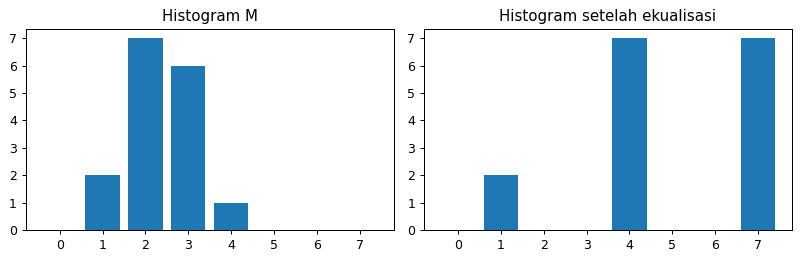

In [7]:
M = np.array([[1, 2, 2, 3], [2, 2, 3, 3], [1, 2, 3, 4], [2, 3, 3, 2]])
L = 8
nilai, n = np.unique(M, return_counts=True)
print("a) histogram:", dict(zip(nilai.tolist(), n.tolist())))
regang = np.floor((M - M.min()) / (M.max() - M.min()) * (L - 1) + 0.5).astype(int)
print("b) peregangan:\n", regang)
pdf = n / M.size; cdf = np.cumsum(pdf)
s_eq = np.floor((L - 1) * cdf + 0.5).astype(int)
tab = pd.DataFrame({"r": nilai, "n": n, "PDF": pdf, "CDF": cdf, "7xCDF": (L - 1) * cdf, "s": s_eq})
display(tab)
peta = dict(zip(nilai, s_eq))
print("c) hasil ekualisasi:\n", np.vectorize(peta.get)(M))
gam = lambda r, g: 255 * (r / 255) ** g
print("d) negatif r=60 ->", 255 - 60,
      "| kontras r=120 ->", 1.4 * 120 - 30, "| kontras r=210 ->", min(1.4 * 210 - 30, 255),
      "| gamma 0.6 r=100 ->", round(gam(100, 0.6), 2), "| gamma 1.8 r=100 ->", round(gam(100, 1.8), 2))
plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1); plt.bar(range(8), np.bincount(M.ravel(), minlength=8)); plt.title("Histogram M")
plt.subplot(1, 2, 2); plt.bar(range(8), np.bincount(np.vectorize(peta.get)(M).ravel(), minlength=8))
plt.title("Histogram setelah ekualisasi"); plt.tight_layout(); plt.show()

### Jawaban Lembar Hitung Bagian 3

* **a) Histogram M:** h(1) = 2, h(2) = 7, h(3) = 6, h(4) = 1, total 16 piksel.
* **b) Peregangan** s = (r - 1)/3 x 7: 1 menjadi 0, 2 menjadi 2,33 (2), 3 menjadi 4,67 (5), 4 menjadi 7. Hasilnya [[0,2,2,5],[2,2,5,5],[0,2,5,7],[2,5,5,2]].
* **c) Ekualisasi:** lihat tabel keluaran (s = 1, 4, 7, 7). Hasilnya [[1,4,4,7],[4,4,7,7],[1,4,7,7],[4,7,7,4]].
* **d) Operasi titik:** negatif r = 60 menjadi **195**; kontras r = 120 menjadi **138**; r = 210 menjadi 264, dipotong **255**; gamma 0,6 pada r = 100 menjadi **145**; gamma 1,8 pada r = 100 menjadi **47**.

### Kode 3.1 Statistik dan histogram untuk diagnosis

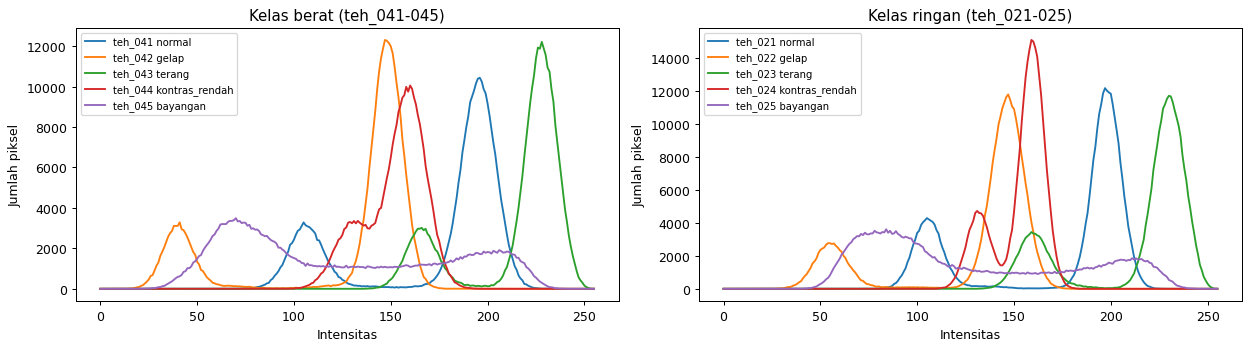

,Citra,Kondisi,Rerata,Simp. baku,Min-maks,% gelap,% terang,Diagnosis,Usulan perbaikan
0,teh_041.png,normal,174.0,38.7,65-238,0.0,9.6,baik,tidak perlu perbaikan berat
1,teh_042.png,gelap,125.7,44.1,9-183,17.6,0.0,terlalu gelap,"gamma < 1 (mis. 0,6)"
2,teh_043.png,terang,215.1,26.0,127-254,0.0,78.9,terlalu terang,"gamma > 1 (mis. 1,6)"
3,teh_044.png,kontras_rendah,152.0,15.5,90-207,0.0,0.0,kontras rendah,peregangan kontras / CLAHE
4,teh_045.png,bayangan,122.5,55.9,19-242,4.0,9.8,cahaya tidak merata,"CLAHE (clip 1, tile 4)"
5,teh_021.png,normal,173.1,41.3,72-235,0.0,10.9,baik,tidak perlu perbaikan berat
6,teh_022.png,gelap,128.8,37.0,15-183,4.6,0.0,baik,tidak perlu perbaikan berat
7,teh_023.png,terang,213.7,30.4,125-255,0.0,76.4,terlalu terang,"gamma > 1 (mis. 1,6)"
8,teh_024.png,kontras_rendah,152.9,13.3,108-187,0.0,0.0,kontras rendah,peregangan kontras / CLAHE
9,teh_025.png,bayangan,126.9,53.4,36-246,0.2,12.6,cahaya tidak merata,"CLAHE (clip 1, tile 4)"


In [8]:
def diagnosis(st):
    if st["simpangan_baku"] < 20:                 return "kontras rendah", "peregangan kontras / CLAHE"
    if st["persen_terang"] > 40:                  return "terlalu terang", "gamma > 1 (mis. 1,6)"
    if st["persen_gelap"] > 10 or st["maks"] < 170: return "terlalu gelap", "gamma < 1 (mis. 0,6)"
    if st["simpangan_baku"] > 50:                 return "cahaya tidak merata", "CLAHE (clip 1, tile 4)"
    return "baik", "tidak perlu perbaikan berat"

baris = []
plt.figure(figsize=(14, 4))
for i, nama in enumerate(["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"]
                         + [f"teh_0{k}.png" for k in range(21, 26)]):
    gr = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    st = statistik(gr); dg, us = diagnosis(st)
    kond = label.set_index("nama_file").loc[nama, "kondisi_cahaya"]
    baris.append([nama, kond, st["rerata"], st["simpangan_baku"], f'{st["min"]}-{st["maks"]}',
                  st["persen_gelap"], st["persen_terang"], dg, us])
    plt.subplot(1, 2, 1 if i < 5 else 2)
    plt.plot(cv2.calcHist([gr], [0], None, [256], [0, 256]), label=f"{nama[:7]} {kond}")
for k, jd in [(1, "Kelas berat (teh_041-045)"), (2, "Kelas ringan (teh_021-025)")]:
    plt.subplot(1, 2, k); plt.title(jd); plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("../hasil/b3_histogram_5kondisi.png", bbox_inches="tight"); plt.show()
diag = pd.DataFrame(baris, columns=["Citra", "Kondisi", "Rerata", "Simp. baku", "Min-maks",
                                    "% gelap", "% terang", "Diagnosis", "Usulan perbaikan"])
diag.to_csv("../hasil/b3_diagnosis.csv", index=False); display(diag)

### Kode 3.2 Operasi titik, peregangan, gamma, ekualisasi, dan CLAHE (citra bayangan teh_045)

,Metode,Parameter,KB,Simpangan baku,Pengamatan visual
0,asli,-,2.19,55.9,"sisi kanan teduh, bercak di sisi teduh samar"
1,negatif,s = 255 - r,2.19,55.9,hanya membalik; KB tetap
2,cerah+50,b = 50,2.19,54.4,semua naik; area terang terpotong di 255
3,kontras,"a = 1,5; b = -40",2.19,79.2,kontras global naik; sisi terang jenuh
4,regang,persentil 2-98,2.28,80.6,rentang penuh dipakai; sisi teduh tetap gelap
5,gamma0.5,"gamma = 0,5",1.84,40.7,sisi teduh lebih cerah tetapi daun ikut pucat
6,gamma1.8,"gamma = 1,8",2.90,59.4,daun lebih gelap sehingga bercak terang lebih ...
7,ekualisasi,global,1.57,73.4,beda sisi terang-teduh justru diperkuat
8,CLAHE,clip 2; tile 8,2.25,47.0,kecerahan lokal lebih rata; bercak sisi teduh ...


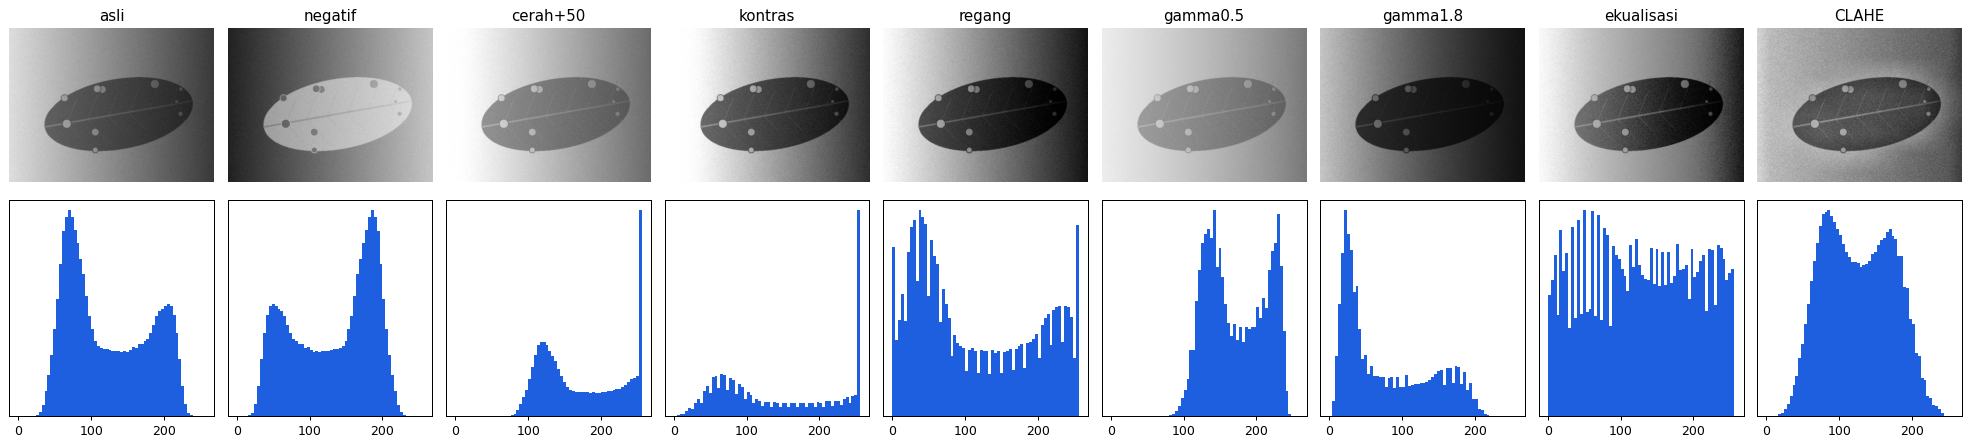

In [9]:
nama = "teh_045.png"
img, md, mb = muat(nama)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))
hasil = {
    "asli": (gray, "-"),
    "negatif": (255 - gray, "s = 255 - r"),
    "cerah+50": (cv2.add(gray, 50), "b = 50"),
    "kontras": (cv2.convertScaleAbs(gray, alpha=1.5, beta=-40), "a = 1,5; b = -40"),
    "regang": (np.clip((gray - rmin) / (rmax - rmin) * 255, 0, 255).astype(np.uint8), "persentil 2-98"),
    "gamma0.5": (cv2.LUT(gray, gamma_lut(0.5)), "gamma = 0,5"),
    "gamma1.8": (cv2.LUT(gray, gamma_lut(1.8)), "gamma = 1,8"),
    "ekualisasi": (cv2.equalizeHist(gray), "global"),
    "CLAHE": (cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray), "clip 2; tile 8"),
}
catatan = {"asli": "sisi kanan teduh, bercak di sisi teduh samar",
           "negatif": "hanya membalik; KB tetap",
           "cerah+50": "semua naik; area terang terpotong di 255",
           "kontras": "kontras global naik; sisi terang jenuh",
           "regang": "rentang penuh dipakai; sisi teduh tetap gelap",
           "gamma0.5": "sisi teduh lebih cerah tetapi daun ikut pucat",
           "gamma1.8": "daun lebih gelap sehingga bercak terang lebih menonjol",
           "ekualisasi": "beda sisi terang-teduh justru diperkuat",
           "CLAHE": "kecerahan lokal lebih rata; bercak sisi teduh lebih jelas"}
baris = [[nm, par, round(kontras_bercak(c, md, mb), 2), round(c.std(), 1), catatan[nm]]
         for nm, (c, par) in hasil.items()]
tab_b3 = pd.DataFrame(baris, columns=["Metode", "Parameter", "KB", "Simpangan baku", "Pengamatan visual"])
tab_b3.to_csv("../hasil/b3_perbaikan.csv", index=False); display(tab_b3)

fig, ax = plt.subplots(2, 9, figsize=(22, 5.2))
for i, (nm, (c, _)) in enumerate(hasil.items()):
    ax[0, i].imshow(c, cmap="gray", vmin=0, vmax=255); ax[0, i].set_title(nm); ax[0, i].axis("off")
    ax[1, i].hist(c.ravel(), bins=64, range=(0, 256), color="#1E5FE0"); ax[1, i].set_yticks([])
plt.tight_layout(); plt.savefig("../hasil/b3_histogram.png", bbox_inches="tight"); plt.show()

### Kode 3.3 Eksperimen CLAHE dan CLAHE pada citra warna

tile,4,8,16
clipLimit,,,
1.0,2.49,2.62,2.68
2.0,2.25,2.25,2.21
4.0,1.81,1.67,1.80


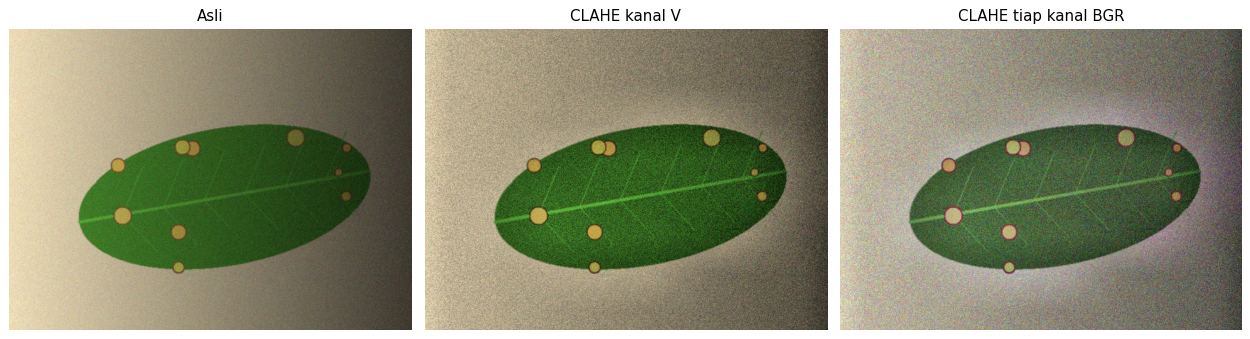

,Hue daun,Hue bercak,Saturasi daun
Asli,51.4,25.3,175.0
CLAHE kanal V,51.4,25.3,176.5
CLAHE tiap kanal,60.3,51.8,130.3


In [10]:
baris = []
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        baris.append([clip, tile, round(kontras_bercak(c, md, mb), 2)])
tab_clahe = pd.DataFrame(baris, columns=["clipLimit", "tile", "KB"]).pivot(index="clipLimit", columns="tile", values="KB")
display(tab_clahe)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])
plt.savefig("../hasil/b3_clahe_warna.png", bbox_inches="tight"); plt.show()

# bukti: pergeseran Hue di area daun dan area bercak
def hue_rerata(im, mask):
    hh = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)[:, :, 0].astype(float)
    return hh[mask].mean()
daun = (md > 0) & (mb == 0); brc = mb > 0
bukti = pd.DataFrame({
    "Hue daun": [hue_rerata(x, daun) for x in (img, via_v, via_bgr)],
    "Hue bercak": [hue_rerata(x, brc) for x in (img, via_v, via_bgr)],
    "Saturasi daun": [cv2.cvtColor(x, cv2.COLOR_BGR2HSV)[:, :, 1][daun].mean() for x in (img, via_v, via_bgr)],
}, index=["Asli", "CLAHE kanal V", "CLAHE tiap kanal"]).round(1)
display(bukti)

### Langkah 3.5 Perbaikan per kondisi untuk kelas berat dan kelas ringan

,Kondisi,Citra,Kelas,Perbaikan,KB sebelum,KB sesudah
0,gelap,teh_042.png,berat,"gamma 0,6",5.46,4.41
1,gelap,teh_022.png,ringan,"gamma 0,6",1.60,1.32
2,terang,teh_043.png,berat,"gamma 1,6",3.16,3.37
3,terang,teh_023.png,ringan,"gamma 1,6",2.63,2.80
4,kontras_rendah,teh_044.png,berat,peregangan 2-98,1.41,1.49
5,kontras_rendah,teh_024.png,ringan,peregangan 2-98,1.67,1.79
6,bayangan,teh_045.png,berat,CLAHE clip 1 tile 4,2.19,2.49
7,bayangan,teh_025.png,ringan,CLAHE clip 1 tile 4,0.11,0.65


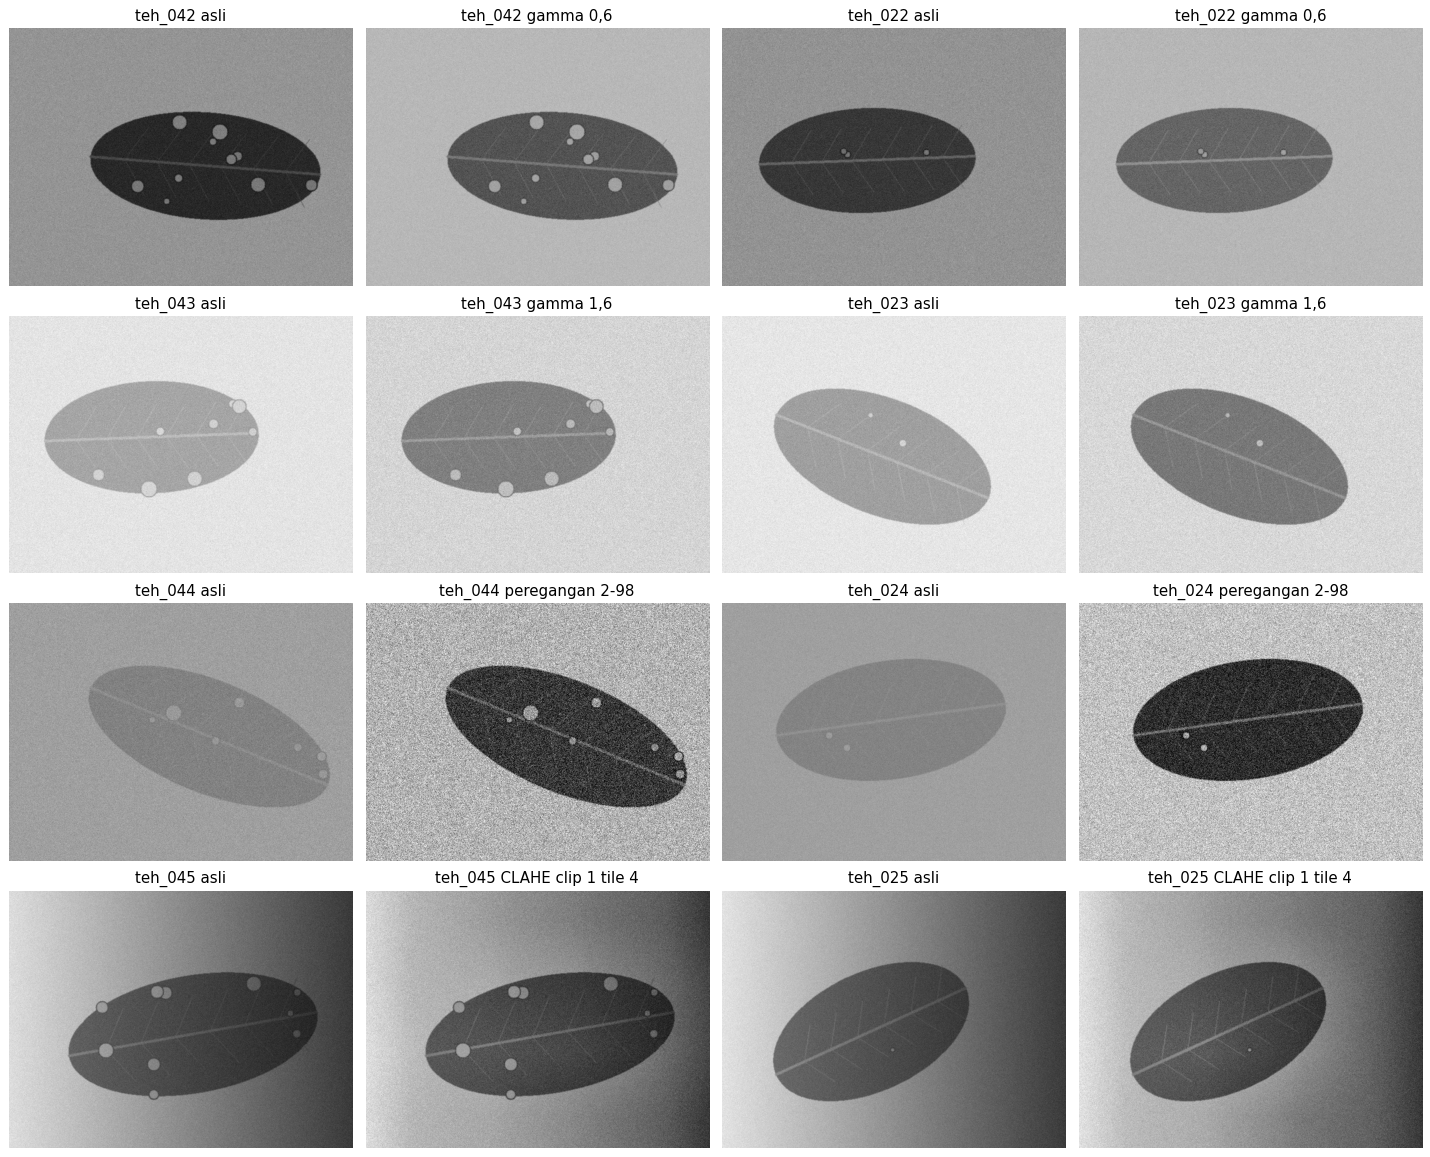

In [11]:
clahe_lokal = cv2.createCLAHE(clipLimit=1.0, tileGridSize=(4, 4))
def regang_p(x):
    lo, hi = np.percentile(x, (2, 98))
    return np.clip((x - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)
pilihan = {
    "gelap":          ("gamma 0,6", lambda x: cv2.LUT(x, gamma_lut(0.6)), ["teh_042.png", "teh_022.png"]),
    "terang":         ("gamma 1,6", lambda x: cv2.LUT(x, gamma_lut(1.6)), ["teh_043.png", "teh_023.png"]),
    "kontras_rendah": ("peregangan 2-98", regang_p,                     ["teh_044.png", "teh_024.png"]),
    "bayangan":       ("CLAHE clip 1 tile 4", clahe_lokal.apply,        ["teh_045.png", "teh_025.png"]),
}
baris, daftar, judul = [], [], []
for kond, (nm_m, fn, citra) in pilihan.items():
    for nama in citra:
        im, m_d, m_b = muat(nama)
        gr = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY); out = fn(gr)
        kelas = label.set_index("nama_file").loc[nama, "kelas"]
        baris.append([kond, nama, kelas, nm_m, round(kontras_bercak(gr, m_d, m_b), 2), round(kontras_bercak(out, m_d, m_b), 2)])
        daftar += [gr, out]; judul += [f"{nama[:7]} asli", f"{nama[:7]} {nm_m}"]
tab_35 = pd.DataFrame(baris, columns=["Kondisi", "Citra", "Kelas", "Perbaikan", "KB sebelum", "KB sesudah"])
display(tab_35)
tampil(daftar, judul, baris=4, ukuran=(16, 13))
plt.savefig("../hasil/b3_perbaikan_per_kondisi.png", bbox_inches="tight"); plt.show()

### Jawaban Pertanyaan Analisis Bagian 3

**P3.1** Nilai 3 dan 4 sama-sama menjadi 7 karena CDF level 3 sudah 0,9375 sehingga 7 x 0,9375 dibulatkan menjadi 7. Perbedaan antara kedua level itu **hilang permanen** dan tidak dapat dikembalikan. Ekualisasi hanya memindahkan letak level berdasarkan CDF; ia tidak menciptakan level baru, dapat menggabungkan level yang jarang muncul (level 4 hanya 1 piksel), dan tidak menjamin seluruh rentang terpakai (level terendah menjadi 1, bukan 0). Jadi ekualisasi tidak menambah informasi, hanya menata ulang tampilan.

**P3.2** Histogram citra bayangan (teh_045) melebar dan cenderung dua kelompok, yaitu sisi terang dan sisi teduh (simpangan baku 54, rentang 28 sampai 236). Ekualisasi global memakai satu CDF untuk seluruh citra, sehingga perbedaan populasi terbesar, yaitu sisi terang lawan sisi teduh, yang paling diperkuat, bukan perbedaan bercak lawan daun. Hasilnya KB turun dari 2,86 menjadi **1,86**. CLAHE menghitung ekualisasi per blok dengan batas penguatan, sehingga kontras lokal di sisi teduh ikut diperbaiki: KB naik menjadi 3,09 (clip 2, tile 8) dan **3,55 (clip 1, tile 4)**. Ini sama dengan kasus kebun teh pada slide P3: separuh daun terkena matahari dan separuh dalam bayangan, sehingga metode lokal lebih tepat.

**P3.3** Peregangan min-maks gagal bila ada sedikit piksel ekstrem. Contohnya, daun bernilai 100 sampai 160, tetapi ada satu piksel mati bernilai 0 dan satu pantulan cahaya bernilai 255. Maka r_min = 0 dan r_maks = 255, sehingga s = r dan tidak ada peregangan sama sekali. Dengan persentil 2 dan 98, r_min sekitar 100 dan r_maks sekitar 160, sehingga 100 menjadi 0, 130 menjadi 128, dan 160 menjadi 255. Kontras daun benar-benar meningkat.

**P3.4** Bukti dari Kode 3.3: CLAHE pada kanal V tidak mengubah Hue (daun tetap 53,3 dan bercak tetap 23,9). CLAHE pada tiap kanal B, G, R mengubah Hue bercak dari **23,9 (kuning) menjadi 57,3 (hijau)** dan menurunkan saturasi daun dari 185 menjadi 137. Ekualisasi per kanal mengubah rasio antarkanal sehingga warna bergeser. Akibatnya bercak tampak hijau seperti daun sehat, yang fatal bagi SIMUTEH. Kanal V hanya membawa kecerahan, sehingga warna aman.

**P3.5** Satu pengaturan tidak cukup. Hasil Langkah 3.5 menunjukkan:
* gamma 1,6 membantu kondisi terang (KB 4,09 menjadi 4,37 pada berat; 2,56 menjadi 2,73 pada ringan);
* gamma 0,6 mencerahkan citra gelap secara visual, tetapi KB keabuan turun (5,78 menjadi 4,75) karena keragaman daun ikut melebar;
* peregangan hanya sedikit membantu kontras rendah (1,84 menjadi 1,97);
* CLAHE membantu bayangan kelas berat (2,86 menjadi 3,55), tetapi sedikit menurunkan kelas ringan (2,90 menjadi 2,74).

Aturan sederhana berbasis statistik histogram, yang dipakai pada fungsi `diagnosis()` dan diterapkan otomatis di Bagian 5:
* simpangan baku < 20 berarti **kontras rendah**, tangani dengan peregangan;
* persen terang > 40 berarti **terlalu terang**, tangani dengan gamma 1,6;
* persen gelap > 10 atau maksimum < 170 berarti **terlalu gelap**, tangani dengan gamma 0,6;
* simpangan baku > 50 berarti **cahaya tidak merata**, tangani dengan CLAHE (clip 1, tile 4);
* selain itu tanpa perbaikan.

Aturan ini mendiagnosis kesepuluh citra uji dengan benar.

**P3.6** Contoh perbaikan berlebihan: CLAHE dengan clip besar atau ekualisasi global pada daun sehat memperkuat tulang daun dan kilap permukaan, sehingga muncul garis dan titik terang yang mirip bercak. Uji pencilan di Bagian 5 menunjukkan bahwa piksel "mirip bercak" memang muncul di tulang daun dan tepi daun. Sebaliknya, gamma yang terlalu besar dapat membuat bercak kecil yang pucat menyatu dengan daun. Pencegahannya:
* simpan citra mentah;
* terapkan rangkaian dan parameter yang sama pada semua citra;
* batasi clip CLAHE;
* uji praproses pada kelas sehat (persen bercak harus mendekati 0);
* bandingkan dengan mask acuan;
* catat semua parameter.